# TP3 – CNN on MNIST (Keras)
This notebook demonstrates how to build and train a **Convolutional Neural Network (CNN)** on the **MNIST** dataset using **TensorFlow/Keras**.

By the end of this notebook, you will:
- Understand CNN architecture
- Build a CNN with convolution and pooling layers
- Train the CNN and evaluate its accuracy
- Visualize convolutional filters and feature maps

## Import required libraries

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [16]:
datagen = ImageDataGenerator(
    rotation_range=0,        # No rotation for digits (could confuse 6/9)
    zoom_range=0.1,         # Random zoom ±10%
    width_shift_range=0.1,  # Horizontal shift ±10%
    height_shift_range=0.1, # Vertical shift ±10%
    rescale=1./255          # Normalize pixel values
)

In [17]:
datagen.fit(x_train)

## Load and preprocess MNIST data

In [18]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Reshape for CNN input (batch, height, width, channels)
x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0
x_test = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0

# One-hot encode the labels
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

## Build the CNN model

In [ ]:
model = Sequential()
model.add(Conv2D(32, kernel_size=(3,3), activation='relu', input_shape=(28,28,1)))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Conv2D(64, kernel_size=(3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

# Train the CNN model

In [ ]:
history = model.fit(x_train, y_train,
                    epochs=10,
                    batch_size=128,
                    validation_split=0.2,
                    verbose=2)

Epoch 1/10
375/375 - 40s - 106ms/step - accuracy: 0.8982 - loss: 0.3347 - val_accuracy: 0.9737 - val_loss: 0.0858
Epoch 2/10
375/375 - 41s - 108ms/step - accuracy: 0.9684 - loss: 0.1078 - val_accuracy: 0.9837 - val_loss: 0.0546
Epoch 3/10
375/375 - 39s - 105ms/step - accuracy: 0.9770 - loss: 0.0755 - val_accuracy: 0.9870 - val_loss: 0.0460
Epoch 4/10
375/375 - 43s - 115ms/step - accuracy: 0.9802 - loss: 0.0648 - val_accuracy: 0.9887 - val_loss: 0.0389
Epoch 5/10
375/375 - 40s - 106ms/step - accuracy: 0.9841 - loss: 0.0538 - val_accuracy: 0.9893 - val_loss: 0.0381
Epoch 6/10
375/375 - 42s - 113ms/step - accuracy: 0.9860 - loss: 0.0478 - val_accuracy: 0.9902 - val_loss: 0.0365
Epoch 7/10
375/375 - 39s - 104ms/step - accuracy: 0.9868 - loss: 0.0435 - val_accuracy: 0.9905 - val_loss: 0.0375
Epoch 8/10
375/375 - 41s - 110ms/step - accuracy: 0.9877 - loss: 0.0379 - val_accuracy: 0.9892 - val_loss: 0.0385
Epoch 9/10
375/375 - 40s - 107ms/step - accuracy: 0.9888 - loss: 0.0350 - val_accuracy: 

## Evaluate the model

In [ ]:

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")

Test Accuracy: 0.9926


In [19]:
model = Sequential()
model.add(Conv2D(32, kernel_size=(3,3),activation='relu', input_shape=(28,28,1)))
model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(64, kernel_size=(3,3),activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(BatchNormalization())

model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))


model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,930 (882.54 KB)

 Trainable params: 225,482 (880.79 KB)

 Non-trainable params: 448 (1.75 KB)

In [20]:
history = model.fit(x_train, y_train,
                    batch_size=128,
                    epochs=10,
                    validation_data=(x_test, y_test))

score = model.evaluate(x_test, y_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 76s 156ms/step - accuracy: 0.8936 - loss: 0.3631 - val_accuracy: 0.7117 - val_loss: 0.7913
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 156ms/step - accuracy: 0.9811 - loss: 0.0633 - val_accuracy: 0.9874 - val_loss: 0.0340
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 79s 149ms/step - accuracy: 0.9867 - loss: 0.0465 - val_accuracy: 0.9877 - val_loss: 0.0394
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 71s 152ms/step - accuracy: 0.9896 - loss: 0.0342 - val_accuracy: 0.9880 - val_loss: 0.0388
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 84s 157ms/step - accuracy: 0.9917 - loss: 0.0276 - val_accuracy: 0.9829 - val_loss: 0.0525
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 79s 151ms/step - accuracy: 0.9926 - loss: 0.0247 - val_accuracy: 0.9924 - val_loss: 0.0254
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 83s 153ms/step - accuracy: 0.9934 - loss: 0.0211 - val_accuracy: 0.9864 - val_loss: 0.0397
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 83s 156ms/step - accuracy: 0.9944 - loss: 0

In [9]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")

Test Accuracy: 0.9927


## Plot accuracy curves

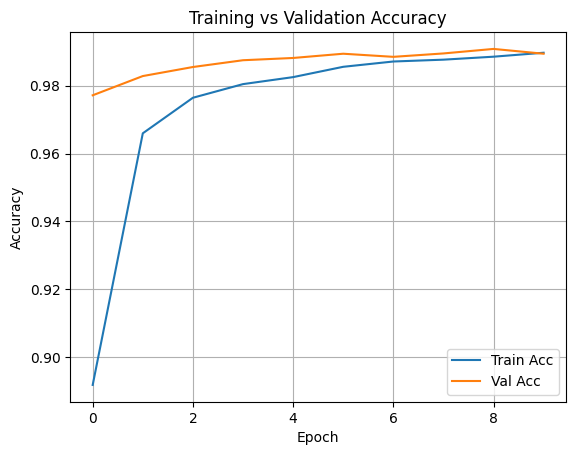

In [ ]:

plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, Activation

# 1. Data Augmentation Setup (using your parameters)
datagen = ImageDataGenerator(
    rotation_range=0,        # No rotation for digits (could confuse 6/9)
    zoom_range=0.1,         # Random zoom ±10%
    width_shift_range=0.1,  # Horizontal shift ±10%
    height_shift_range=0.1, # Vertical shift ±10%
    rescale=1./255          # Normalize pixel values
)

# Fit to your training data (assuming x_train is numpy array)
datagen.fit(x_train)

# 2. Enhanced Model Architecture
model = Sequential([
    # First Conv Block
    Conv2D(32, (3,3), input_shape=(28,28,1)),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2,2)),
    Dropout(0.25),

    # Second Conv Block
    Conv2D(64, (3,3)),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2,2)),
    Dropout(0.25),

    # Classifier
    Flatten(),
    Dense(128),
    BatchNormalization(),
    Activation('relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
             loss='categorical_crossentropy',
             metrics=['accuracy'])

# 3. Training with Augmentation
batch_size = 128
history = model.fit(
    datagen.flow(x_train, y_train, batch_size=batch_size),
    steps_per_epoch=len(x_train) // batch_size,
    epochs=20,
    validation_data=(x_test/255., y_test)  # Don't augment test data
)

# 4. Evaluation
score = model.evaluate(x_test/255., y_test, verbose=0)
print(f'Test accuracy: {score[1]:.4f}')